In [ ]:
import copy
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import rl_mind.envs
from dataclasses import dataclass, replace
from scipy import stats
from torch import Tensor
import gymnasium as gym
from torch.utils.tensorboard import SummaryWriter
from tqdm.auto import tqdm
from rl_mind.core import Action, Actor
from rl_mind.nn import build_mlp, soft_update
from rl_mind.env import VecEnv
from rl_mind.data import ReplayBuffer, Transitions
from rl_mind.collectors import TransitionCollector
from rl_mind.evaluation import Evaluator
from rl_mind.notebook import run_directory, silence_known_warnings


In [ ]:
silence_known_warnings()

In [ ]:
env = gym.make("LunarLander-v3", continuous=True)

print("Observation space:", env.observation_space)
print("Action space:", env.action_space)

obs, info = env.reset(seed=0)
print("Example observation:", obs)
print("Example random action:", env.action_space.sample())

Observation space: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Action space: Box(-1.0, 1.0, (2,), float32)
Example observation: [ 0.00570612  1.3990337   0.5779653  -0.5282997  -0.0066053  -0.13091765
  0.          0.        ]
Example random action: [-0.01213543 -0.7392225 ]


In [ ]:
def add_layernorm(model: nn.Module):
    layers = list(model.children())
    linear_indices = [i for i, layer in enumerate(layers)if isinstance(layer, nn.Linear)]
    last_linear_index = linear_indices[-1]
    new_layers = []
    for i, layer in enumerate(layers):
        new_layers.append(layer)
        if isinstance(layer, nn.Linear) and i != last_linear_index:
            new_layers.append(nn.LayerNorm(layer.out_features))
    return nn.Sequential(*new_layers)

In [ ]:
class ContinuousQNetwork(nn.Module):
    def __init__(self, obs_dim: int, hidden: tuple[int, ...], action_dim: int, use_layernorm: bool = False):
        super().__init__()
        self.model = build_mlp([obs_dim + action_dim, *hidden, 1])
        if use_layernorm:
            self.model = add_layernorm(self.model)

    def forward(self, obs: Tensor, action: Tensor) -> Tensor:
        return self.model(torch.cat([obs, action], dim=1)).squeeze(-1)

In [ ]:
class ContinuousDeterministicActor(Actor[Action]):
    def __init__(self, obs_dim: int, hidden: tuple[int, ...], action_dim: int, use_layernorm: bool = False):
        super().__init__()
        self.model = build_mlp(
            [obs_dim, *hidden, action_dim], output_activation=nn.Tanh()
        )
        if use_layernorm:
            self.model = add_layernorm(self.model)

    def forward(self, obs: Tensor) -> Action:
        return Action(value=self.model(obs))

In [ ]:
class GaussianNoise(Actor[Action]):
    def __init__(self, actor: Actor[Action], sigma: float):
        super().__init__()
        self.actor = actor
        self.sigma = sigma

    def forward(self, obs: Tensor) -> Action:
      action = self.actor(obs).value
      noisy_action = action + self.sigma * torch.randn_like(action)
      return Action(value=noisy_action.clamp(-1.0, 1.0))

    def act(self, obs: Tensor) -> Tensor:
        return self.actor.act(obs)

In [ ]:
def compute_critic_loss(
    gamma: float, batch: Transitions[Action], q_values: Tensor, next_q_values: Tensor
) -> Tensor:
    target = (batch.reward+ gamma * (~batch.terminated) * next_q_values)
    return F.mse_loss(q_values, target)

In [ ]:
def compute_actor_loss(q_values: Tensor) -> Tensor:
    target = -q_values.mean()
    return target

In [ ]:
@dataclass(frozen=True)
class DDPGConfig:
    env_name: str = "LunarLander-v3"
    seed: int = 1

    use_layernorm: bool = False

    max_steps: int = 300_000
    n_envs: int = 1
    steps_per_update: int = 1
    learning_starts: int = 1_000

    buffer_size: int = 200_000
    batch_size: int = 64

    gamma: float = 0.98
    tau: float = 0.05
    action_noise: float = 0.1

    actor_hidden: tuple[int, ...] = (256, 256)
    critic_hidden: tuple[int, ...] = (256, 256)
    lr_actor: float = 1e-3
    lr_critic: float = 1e-3

    eval_interval: int = 2_000
    n_eval_envs: int = 10

In [ ]:
def run_ddpg(cfg: DDPGConfig) -> Evaluator:
    torch.manual_seed(cfg.seed)
    env = VecEnv(cfg.env_name,cfg.n_envs,seed=cfg.seed,continuous=True)

    actor = ContinuousDeterministicActor(
        env.observation_dim, cfg.actor_hidden, env.action_dim, use_layernorm=cfg.use_layernorm
    )
    critic = ContinuousQNetwork(
        env.observation_dim, cfg.critic_hidden, env.action_dim, use_layernorm=cfg.use_layernorm
    )
    target_critic = copy.deepcopy(critic)
    target_actor = copy.deepcopy(actor)

    actor_optimizer = torch.optim.Adam(actor.parameters(), lr=cfg.lr_actor)
    critic_optimizer = torch.optim.Adam(critic.parameters(), lr=cfg.lr_critic)

    collector = TransitionCollector(env, GaussianNoise(actor, cfg.action_noise))
    buffer = ReplayBuffer(cfg.buffer_size)
    ln_name = "LN" if cfg.use_layernorm else "noLN"
    run_dir = run_directory(f"ddpg-{cfg.env_name}-{ln_name}-S{cfg.seed}")
    evaluator = Evaluator(
        VecEnv(cfg.env_name,cfg.n_eval_envs,seed=cfg.seed + 100,continuous=True),
        every=cfg.eval_interval,
        run_dir=run_dir,
        writer=SummaryWriter(run_dir),
    )

    pbar = tqdm(total=cfg.max_steps)
    while collector.steps < cfg.max_steps:
        buffer.add(collector.collect(cfg.steps_per_update))
        pbar.update(collector.steps - pbar.n)
        if len(buffer) < cfg.learning_starts:
            continue

        batch = buffer.sample(cfg.batch_size)

        q_values = critic(batch.obs, batch.action.value)
        with torch.no_grad():
            next_actions = target_actor(batch.next_obs).value
            next_q_values = target_critic(batch.next_obs, next_actions)

        critic_loss = compute_critic_loss(cfg.gamma, batch, q_values, next_q_values)
        critic_optimizer.zero_grad()
        critic_loss.backward()
        critic_optimizer.step()

        actions = actor(batch.obs).value
        q_values = critic(batch.obs, actions)
        actor_loss = compute_actor_loss(q_values)

        actor_optimizer.zero_grad()
        actor_loss.backward()
        actor_optimizer.step()

        soft_update(critic, target_critic, cfg.tau)
        soft_update(actor, target_actor, cfg.tau)

        evaluator.writer.add_scalar("loss/critic", critic_loss.item(), collector.steps)
        evaluator.writer.add_scalar("loss/actor", actor_loss.item(), collector.steps)
        if result := evaluator.run_if_needed(collector.steps, actor):
            pbar.set_description(
                f"eval={result.mean:7.1f} best={evaluator.best_reward:7.1f}"
            )
            mc_env = gym.make(cfg.env_name, continuous=True)
            obs, _ = mc_env.reset(seed=cfg.seed + 1000)

            mc_return = 0.0
            discount = 1.0
            q_pred = None
            done = False

            while not done:
                state = torch.tensor(obs, dtype=torch.float32).unsqueeze(0)

                with torch.no_grad():
                    action = actor(state).value
                    if q_pred is None:
                        q_pred = critic(state, action).item()

                obs, reward, terminated, truncated, _ = mc_env.step(
                    action.squeeze(0).numpy()
                )

                mc_return += discount * reward
                discount *= cfg.gamma
                done = terminated or truncated

            mc_env.close()

            evaluator.writer.add_scalar(
                "Q_vs_MC/Q_value",
                q_pred,
                collector.steps,
            )
            evaluator.writer.add_scalar(
                "Q_vs_MC/Monte_Carlo",
                mc_return,
                collector.steps,
            )
            evaluator.writer.add_scalar(
                "Q_vs_MC/Bias",
                q_pred - mc_return,
                collector.steps,
            )

            evaluator.writer.flush()

            print(
                f"Step {collector.steps}: "
                f"Q={q_pred:.2f}, "
                f"MC={mc_return:.2f}, "
                f"Bias={q_pred - mc_return:.2f}"
            )
    pbar.close()
    return evaluator

In [ ]:
for use_ln in (False, True):
  evaluator = run_ddpg(
      DDPGConfig(seed=0, use_layernorm=use_ln)
  )
  evaluator.writer.close()

  0%|          | 0/300000 [00:00<?, ?it/s]

Step 2000: Q=-4.13, MC=-33.86, Bias=29.73
Step 4000: Q=30.45, MC=-9.73, Bias=40.19
Step 6000: Q=48.76, MC=-50.19, Bias=98.95
Step 8000: Q=91.40, MC=2.69, Bias=88.71
Step 10000: Q=120.46, MC=-10.44, Bias=130.89
Step 12000: Q=127.27, MC=7.48, Bias=119.79
Step 14000: Q=115.77, MC=0.83, Bias=114.94
Step 16000: Q=134.87, MC=-35.21, Bias=170.08
Step 18000: Q=99.49, MC=2.19, Bias=97.30
Step 20000: Q=89.77, MC=-4.72, Bias=94.49
Step 22000: Q=99.76, MC=-13.02, Bias=112.79
Step 24000: Q=122.39, MC=3.26, Bias=119.14
Step 26000: Q=105.05, MC=8.28, Bias=96.78
Step 28000: Q=107.67, MC=16.17, Bias=91.50
Step 30000: Q=102.64, MC=6.69, Bias=95.95
Step 32000: Q=97.93, MC=10.94, Bias=86.99
Step 34000: Q=104.41, MC=16.09, Bias=88.32
Step 36000: Q=95.20, MC=17.29, Bias=77.92
Step 38000: Q=102.51, MC=11.95, Bias=90.56
Step 40000: Q=100.96, MC=15.61, Bias=85.35
Step 42000: Q=88.71, MC=-30.90, Bias=119.61
Step 44000: Q=87.89, MC=-39.51, Bias=127.40
Step 46000: Q=95.45, MC=-41.68, Bias=137.13
Step 48000: Q=76.

  0%|          | 0/300000 [00:00<?, ?it/s]

Step 2000: Q=-16.38, MC=-74.90, Bias=58.52
Step 4000: Q=53.56, MC=-13.51, Bias=67.07
Step 6000: Q=48.53, MC=15.83, Bias=32.71
Step 8000: Q=51.95, MC=5.71, Bias=46.24
Step 10000: Q=60.09, MC=-48.89, Bias=108.98
Step 12000: Q=53.08, MC=19.77, Bias=33.31
Step 14000: Q=53.41, MC=13.45, Bias=39.96
Step 16000: Q=62.69, MC=19.16, Bias=43.54
Step 18000: Q=96.72, MC=17.42, Bias=79.31
Step 20000: Q=68.85, MC=15.63, Bias=53.23
Step 22000: Q=52.73, MC=13.10, Bias=39.63
Step 24000: Q=44.89, MC=15.38, Bias=29.51
Step 26000: Q=55.04, MC=17.40, Bias=37.64
Step 28000: Q=45.46, MC=16.57, Bias=28.89
Step 30000: Q=47.28, MC=13.34, Bias=33.94
Step 32000: Q=46.85, MC=14.30, Bias=32.54
Step 34000: Q=47.62, MC=12.30, Bias=35.32
Step 36000: Q=32.21, MC=20.45, Bias=11.76
Step 38000: Q=34.88, MC=11.35, Bias=23.54
Step 40000: Q=33.13, MC=14.27, Bias=18.86
Step 42000: Q=38.08, MC=3.26, Bias=34.82
Step 44000: Q=43.06, MC=15.20, Bias=27.85
Step 46000: Q=37.53, MC=9.91, Bias=27.61
Step 48000: Q=35.75, MC=22.81, Bias=

In [ ]:
from pathlib import Path
import re
import numpy as np
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

LOG_ROOT = Path(".")  # Folder containing your experiment logs
SEEDS = range(1)

runs = {"noLN": {}, "LN": {}}
selected = {}

pattern = re.compile(
    r"^ddpg-LunarLander-v3-(noLN|LN)-S([0-4])(?:-|$)"
)

folders = {
    file.parent
    for file in LOG_ROOT.rglob("events.out.tfevents.*")
}

for folder in sorted(folders):
    match = pattern.match(folder.name)
    if match is None:
        continue

    reader = EventAccumulator(
        str(folder), size_guidance={"scalars": 0}
    )
    reader.Reload()

    data = {
        tag: {event.step: event.value for event in reader.Scalars(tag)}
        for tag in reader.Tags()["scalars"]
    }

    rewards = data.get("eval/reward", {})
    if max(rewards, default=0) < 300_000:
        continue

    condition = match.group(1)
    seed = int(match.group(2))
    runs[condition][seed] = data
    selected[condition, seed] = folder

for condition in runs:
    missing = set(SEEDS) - runs[condition].keys()
    if missing:
        raise ValueError(
            f"Missing completed {condition} runs for seeds {sorted(missing)}. "
            "Check LOG_ROOT or finish the training runs."
        )

    for seed in SEEDS:
        print("Loaded:", selected[condition, seed])

Loaded: outputs/ddpg-LunarLander-v3-noLN-S0-20261013-192138
Loaded: outputs/ddpg-LunarLander-v3-LN-S0-20261013-201643


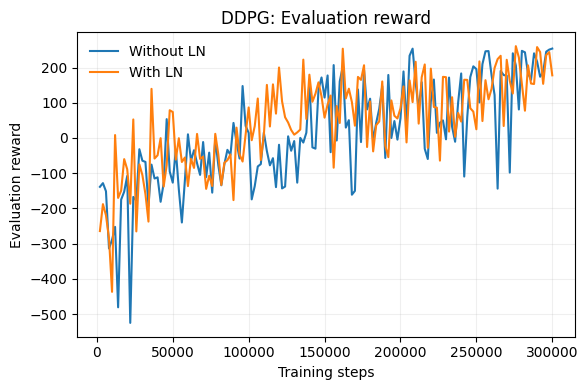

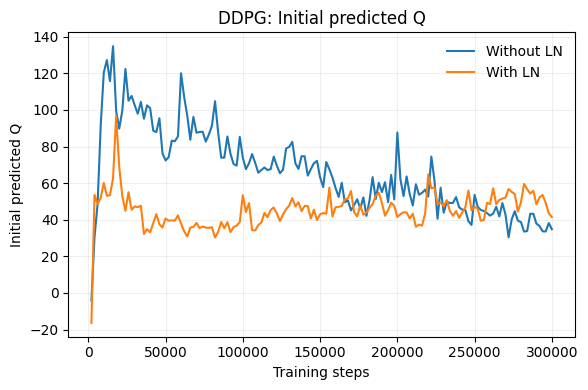

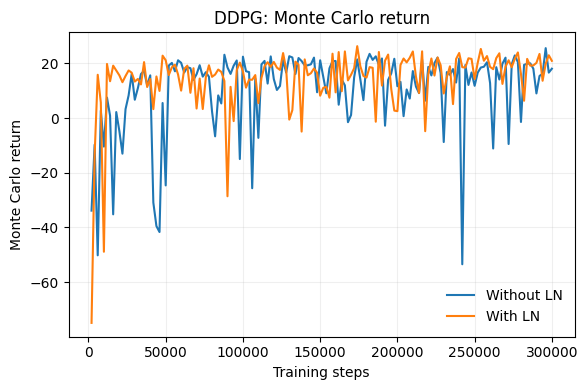

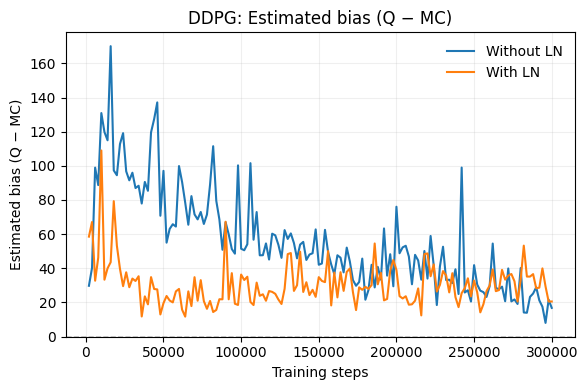

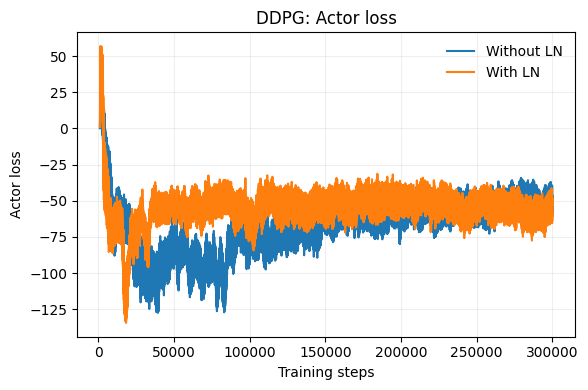

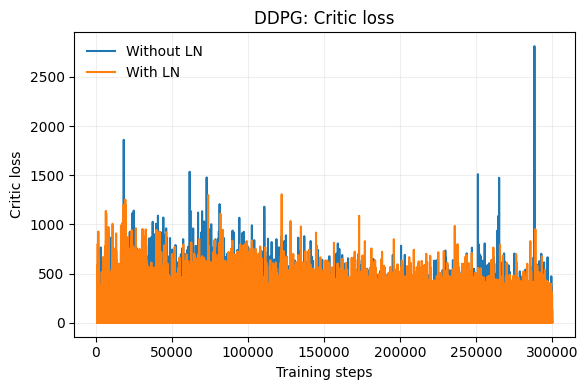

Images saved in: /content/plots


In [ ]:
output_dir = Path("plots")
output_dir.mkdir(exist_ok=True)

metrics = [
    ("eval/reward", "Evaluation reward"),
    ("Q_vs_MC/Q_value", "Initial predicted Q"),
    ("Q_vs_MC/Monte_Carlo", "Monte Carlo return"),
    ("Q_vs_MC/Bias", "Estimated bias (Q − MC)"),
    ("loss/actor", "Actor loss"),
    ("loss/critic", "Critic loss"),
]

for tag, title in metrics:
    fig, ax = plt.subplots(figsize=(6, 4))

    for condition, label, color in [
        ("noLN", "Without LN", "tab:blue"),
        ("LN", "With LN", "tab:orange"),
    ]:
        curves = [runs[condition][seed][tag] for seed in SEEDS]

        steps = sorted(set.intersection(*(set(c) for c in curves)))
        if not steps:
            raise ValueError(f"No shared steps for {condition}: {tag}")

        values = np.array([
            [curve[step] for step in steps]
            for curve in curves
        ])

        mean = values.mean(axis=0)

        ax.plot(steps, mean, label=label, color=color)


    if tag == "Q_vs_MC/Bias":
        ax.axhline(0, color="black", linestyle="--", linewidth=1)

    ax.set_title(f"DDPG: {title}")
    ax.set_xlabel("Training steps")
    ax.set_ylabel(title)
    ax.legend(frameon=False)
    ax.grid(alpha=0.2)
    fig.tight_layout()

    filename = tag.replace("/", "_")
    fig.savefig(output_dir / f"{filename}.png", dpi=300)
    fig.savefig(output_dir / f"{filename}.pdf")

    plt.show()
    plt.close(fig)

print(f"Images saved in: {output_dir.resolve()}")

In [ ]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

folders = [
    Path(name)
    for name in ("outputs", "plots", "plots_td3")
    if Path(name).is_dir()
]

if not folders:
    raise FileNotFoundError("No outputs or plots folders found.")

archive_name = "rl_results.zip"

with ZipFile(archive_name, "w", compression=ZIP_DEFLATED) as archive:
    for folder in folders:
        for file in folder.rglob("*"):
            if file.is_file():
                archive.write(file, arcname=str(file))

print("Included:", ", ".join(str(folder) for folder in folders))

# Download in Colab, or show a download link in Jupyter.
try:
    from google.colab import files
except ImportError:
    from IPython.display import FileLink, display
    display(FileLink(archive_name))
else:
    files.download(archive_name)

Included: outputs, plots


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
from pathlib import Path
from IPython.display import display

ALGORITHM = "TD3"  # Change to "DDPG" in your DDPG notebook

metrics = [
    ("eval/reward", "Evaluation reward"),
    ("Q_vs_MC/Q_value", "Predicted Q"),
    ("Q_vs_MC/Monte_Carlo", "Monte Carlo return"),
    ("Q_vs_MC/Bias", "Estimated bias"),
    ("loss/actor", "Actor loss"),
    ("loss/critic", "Critic loss"),
]

columns = {}

for condition, label in [
    ("noLN", "Without LN"),
    ("LN", "With LN"),
]:
    for seed, history in sorted(runs[condition].items()):
        column = {}

        for tag, name in metrics:
            values = history[tag]
            last_step = max(values)
            column[name] = values[last_step]

        columns[f"{label} — seed {seed}"] = column

table = pd.DataFrame(columns)
table.index.name = "Measure"

print(f"{ALGORITHM}: final logged values")
display(table.round(2))

# Save the full-precision numbers.
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

csv_path = output_dir / f"{ALGORITHM.lower()}_final_values.csv"
table.to_csv(csv_path)

print(f"Numbers saved in: {csv_path}")

TD3: final logged values


,Without LN — seed 0,With LN — seed 0
Measure,,
Evaluation reward,253.79,177.80
Predicted Q,34.83,41.45
Monte Carlo return,18.04,20.91
Estimated bias,16.78,20.53
Actor loss,-53.59,-52.78
Critic loss,4.03,9.37


Numbers saved in: outputs/td3_final_values.csv
